# EmojiHeroVR gameplay performance

Descriptive analysis of recognition success during the recorded EmojiHeroVR study.
Each of the 37 participants reenacted 70 emojis: ten per expression category.
A reenactment succeeds if **at least one logged FER prediction matches its target**.
This measures compatibility with the in-game model, not independently verified
expression quality or the timing of awarded points.


## 1. Setup

Run all cells in order from the notebook directory, with `gameplay-logs.csv`
alongside it. The Python environment is specified in `requirements.txt`.

Figures and tables are always displayed. External exports are disabled by default:
enable `EXPORT_PNG`, `EXPORT_PDF` or `EXPORT_CSV` below as needed.
`EXPORT_METADATA` separately enables a JSON provenance file.


In [ ]:
import hashlib
import importlib.metadata
import json
import platform
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.ticker import PercentFormatter

# Paths are relative to the notebook directory.
INPUT_PATH = Path('gameplay-logs.csv')
FIGURE_DIR = Path('figures')
RESULT_DIR = Path('results')

# External exports are opt-in; notebook displays are always generated.
EXPORT_PNG = False
EXPORT_PDF = False
EXPORT_CSV = False
EXPORT_METADATA = False  # Optional JSON with input hashes and environment details.

CLASS_NAMES = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']
KEYS = ['participant_id', 'level_id', 'emoji_id']
PROB_COLUMNS = [f'prob_{name.lower()}' for name in CLASS_NAMES]

if not INPUT_PATH.is_file():
    raise FileNotFoundError(f'Input log not found: {INPUT_PATH.resolve()}')

versions = {'Python': platform.python_version()}
versions.update(
    {
        name: importlib.metadata.version(name)
        for name in ['numpy', 'pandas', 'matplotlib', 'jupyterlab']
    }
)
display(pd.Series(versions, name='Version').to_frame())


def export_figure(figure, filename, *, title, **save_options):
    """Export only the enabled image formats, using the active plot style."""
    if not (EXPORT_PNG or EXPORT_PDF):
        return
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    if EXPORT_PDF:
        figure.savefig(
            FIGURE_DIR / f'{filename}.pdf',
            metadata={
                'Title': title,
                'Creator': 'Matplotlib',
                'CreationDate': None,
                'ModDate': None,
            },
            **save_options,
        )
    if EXPORT_PNG:
        figure.savefig(FIGURE_DIR / f'{filename}.png', dpi=300, **save_options)

,Version
Python,3.14.8
numpy,2.5.4
pandas,3.0.6
matplotlib,3.11.2
jupyterlab,4.6.4


## 2. Data preparation

### 2.1 Load the prediction log

Each input row represents one logged FER prediction.


In [2]:
logs = pd.read_csv(
    INPUT_PATH,
    dtype={
        'participant_id': 'int64',
        'level_id': 'int64',
        'emoji_id': 'int64',
        'timestamp_unix_ms': 'int64',
        'target_expression': 'string',
        'predicted_expression': 'string',
    },
)

logs.head(n=10)

,participant_id,level_id,emoji_id,timestamp_unix_ms,target_expression,predicted_expression,prob_anger,prob_disgust,prob_fear,prob_happiness,prob_neutral,prob_sadness,prob_surprise,prediction_matches_target,emoji_success
0,1,1,0,1700478995309,Anger,Anger,0.50,0.16,0.00,0.01,0.14,0.17,0.02,True,True
1,1,1,0,1700478995614,Anger,Anger,0.51,0.06,0.01,0.01,0.23,0.17,0.01,True,True
2,1,1,0,1700478995947,Anger,Anger,0.49,0.10,0.01,0.01,0.17,0.21,0.02,True,True
3,1,1,0,1700478996240,Anger,Neutral,0.26,0.01,0.03,0.03,0.46,0.20,0.02,False,True
4,1,1,0,1700478996544,Anger,Sadness,0.29,0.01,0.02,0.02,0.30,0.35,0.02,False,True
5,1,1,1,1700478997812,Sadness,Disgust,0.02,0.82,0.03,0.00,0.01,0.12,0.00,False,True
6,1,1,1,1700478998104,Sadness,Disgust,0.03,0.68,0.02,0.00,0.01,0.26,0.00,False,True
7,1,1,1,1700478998442,Sadness,Sadness,0.04,0.05,0.04,0.00,0.02,0.84,0.01,True,True
8,1,1,1,1700478998743,Sadness,Sadness,0.05,0.23,0.02,0.00,0.02,0.67,0.01,True,True
9,1,1,1,1700478999007,Sadness,Sadness,0.03,0.03,0.01,0.00,0.01,0.91,0.01,True,True


### 2.2 Validate the records

Check identifiers, classes, probabilities and supplied success flags.
Retain failed requests, repeated timestamps and identical rows; the log alone
does not establish that repeated records are duplicates. Order reenactments by
level and emoji ID because one participant has constant timestamps.


In [3]:
required = set(
    KEYS
    + PROB_COLUMNS
    + [
        'timestamp_unix_ms',
        'target_expression',
        'predicted_expression',
        'prediction_matches_target',
        'emoji_success',
    ]
)
missing_columns = required.difference(logs.columns)
if missing_columns:
    raise ValueError(f'Missing columns: {sorted(missing_columns)}')


def parse_boolean(values, name):
    parsed = values.astype('string').str.strip().str.lower().map({'true': True, 'false': False})
    if parsed.isna().any():
        raise ValueError(f'{name} contains missing or invalid boolean values.')
    return parsed.astype(bool)


for name in ['prediction_matches_target', 'emoji_success']:
    logs[name] = parse_boolean(logs[name], name)

if logs.empty or logs[KEYS + ['target_expression']].isna().any().any():
    raise ValueError('The log is empty or has missing identifiers/targets.')
if not logs['target_expression'].isin(CLASS_NAMES).all():
    raise ValueError('Unknown target expression.')
if not logs['predicted_expression'].dropna().isin(CLASS_NAMES).all():
    raise ValueError('Unknown predicted expression.')

probabilities = logs[PROB_COLUMNS].apply(pd.to_numeric, errors='raise')
if not np.isfinite(probabilities.to_numpy()).all():
    raise ValueError('Non-finite probabilities.')
if not probabilities.ge(0).all().all() or not probabilities.le(1).all().all():
    raise ValueError('Probabilities must be between zero and one.')

zero_probability = probabilities.eq(0).all(axis=1)
missing_prediction = logs['predicted_expression'].isna()
if not zero_probability.equals(missing_prediction):
    raise ValueError('Missing predictions and all-zero probability records do not agree.')

# Keep the recorded class: probabilities are rounded, so a new argmax can change ties.
logs['valid_prediction'] = ~missing_prediction
logs['matches_target'] = logs['predicted_expression'].eq(logs['target_expression']).fillna(False)
# Compare values independently of pandas' boolean storage dtype.
if not np.array_equal(
    logs['matches_target'].to_numpy(dtype=bool),
    logs['prediction_matches_target'].to_numpy(dtype=bool),
):
    raise ValueError('prediction_matches_target disagrees with the recorded classes.')

grouped = logs.groupby(KEYS, sort=True)
if not grouped['target_expression'].nunique().eq(1).all():
    raise ValueError('An emoji has multiple target categories.')
if not grouped['emoji_success'].nunique().eq(1).all():
    raise ValueError('emoji_success changes within an emoji.')
any_match = grouped['matches_target'].any()
if not np.array_equal(
    any_match.to_numpy(dtype=bool), grouped['emoji_success'].first().to_numpy(dtype=bool)
):
    raise ValueError('emoji_success disagrees with at least one matching prediction.')

participant_timestamps = logs.groupby('participant_id')['timestamp_unix_ms'].nunique()
quality_counts = {
    'Logged FER records': len(logs),
    'Participants': logs['participant_id'].nunique(),
    'Emoji reenactments': len(grouped),
    'Records without a valid prediction': int(missing_prediction.sum()),
    'Participants with constant timestamps': int(participant_timestamps.eq(1).sum()),
    'Repeated key-and-timestamp rows beyond the first': int(
        logs.duplicated(KEYS + ['timestamp_unix_ms']).sum()
    ),
    'Fully identical rows beyond the first': int(
        logs.drop(columns=['valid_prediction', 'matches_target']).duplicated().sum()
    ),
}
display(pd.Series(quality_counts, name='Count').to_frame())
print('All records are retained. Supplied matching and emoji-success flags are consistent.')

,Count
Logged FER records,20482
Participants,37
Emoji reenactments,2590
Records without a valid prediction,71
Participants with constant timestamps,1
Repeated key-and-timestamp rows beyond the first,253
Fully identical rows beyond the first,2


All records are retained. Supplied matching and emoji-success flags are consistent.


### 2.3 Construct reenactment outcomes

Collapse predictions to one outcome per participant, level and emoji.
`reenactment_number` counts occurrences within each participant and category;
`session_emoji_number` orders all 70 emojis.

Levels 1–4 contain 9, 12, 21 and 28 emojis. Anger, happiness and sadness begin
in Level 1; the remaining categories begin in Level 2. Each category occurs
three times in its introductory level, three times in Level 3 and four times
in Level 4.


In [4]:
emojis = (
    grouped.agg(
        target_expression=('target_expression', 'first'),
        success=('matches_target', 'any'),
        n_valid_predictions=('valid_prediction', 'sum'),
    )
    .reset_index()
    .sort_values(KEYS)
    .reset_index(drop=True)
)

emojis['reenactment_number'] = (
    emojis.groupby(['participant_id', 'target_expression'], sort=False).cumcount() + 1
)

emojis['session_emoji_number'] = emojis.groupby('participant_id', sort=False).cumcount() + 1

n_participants = emojis['participant_id'].nunique()

expected_level_sizes = {1: 9, 2: 12, 3: 21, 4: 28}

for (_, level), block in emojis.groupby(['participant_id', 'level_id']):
    if level not in expected_level_sizes or sorted(block['emoji_id']) != list(
        range(expected_level_sizes[level])
    ):
        raise ValueError('Incomplete or unexpected emoji sequence within a level.')

if not emojis.groupby('participant_id').size().eq(70).all():
    raise ValueError('Expected 70 emojis per participant.')

if not emojis.groupby(['participant_id', 'target_expression']).size().eq(10).all():
    raise ValueError('Expected ten presentations per participant and category.')

if emojis.groupby(['level_id', 'emoji_id'])['target_expression'].nunique().gt(1).any():
    raise ValueError('The fixed target sequence differs between participants.')

total_success = int(emojis['success'].sum())

print(f'{n_participants} participants × 70 emojis = {len(emojis):,} reenactments.')
print(
    f'{total_success:,}/{len(emojis):,} emojis had at least one matching prediction '
    f'({emojis["success"].mean():.2%}).'
)

emojis.head(n=10)

37 participants × 70 emojis = 2,590 reenactments.
1,747/2,590 emojis had at least one matching prediction (67.45%).


,participant_id,level_id,emoji_id,target_expression,success,n_valid_predictions,reenactment_number,session_emoji_number
0,1,1,0,Anger,True,5,1,1
1,1,1,1,Sadness,True,5,1,2
2,1,1,2,Happiness,True,5,1,3
3,1,1,3,Anger,True,5,2,4
4,1,1,4,Anger,True,5,3,5
5,1,1,5,Sadness,False,5,2,6
6,1,1,6,Happiness,True,5,2,7
7,1,1,7,Sadness,True,5,3,8
8,1,1,8,Happiness,True,5,3,9
9,1,2,0,Neutral,True,5,1,10


## 3. Session performance

Each point is the success rate across the same 37 participants for one of the
70 successive emojis. Colours identify categories; dashed lines separate levels.
Category and difficulty vary during the session, so this curve does not isolate learning.


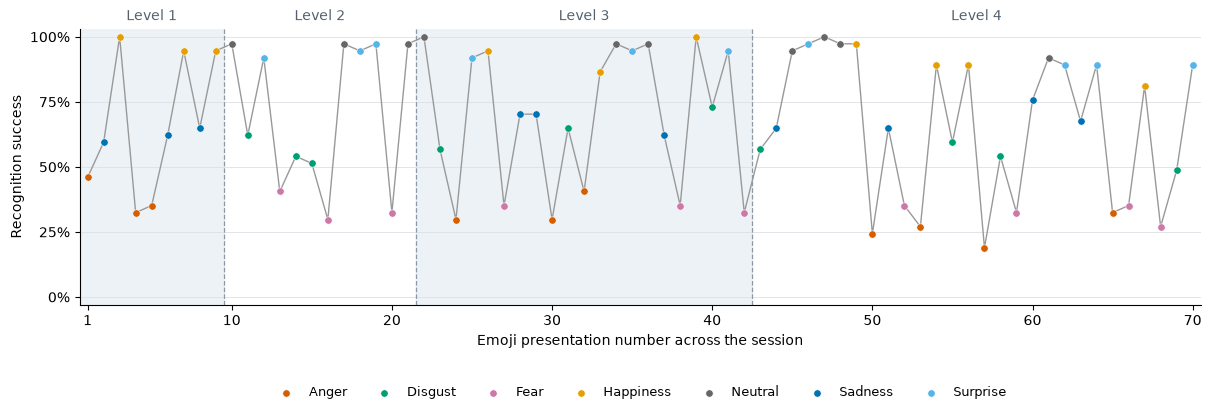

In [5]:
session_success = emojis.groupby('session_emoji_number')['success'].mean().mul(100)

level_ranges = emojis.groupby('level_id')['session_emoji_number'].agg(['min', 'max'])

session_categories = emojis.groupby('session_emoji_number')['target_expression'].first()

category_colours = {
    'Anger': '#D55E00',
    'Disgust': '#009E73',
    'Fear': '#CC79A7',
    'Happiness': '#E69F00',
    'Neutral': '#666666',
    'Sadness': '#0072B2',
    'Surprise': '#56B4E9',
}

with plt.rc_context(
    {
        'font.family': 'DejaVu Sans',
        'font.size': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
        'pdf.fonttype': 42,
    }
):
    fig, ax = plt.subplots(figsize=(12, 4), layout='constrained')

    for level, bounds in level_ranges.iterrows():
        left = bounds['min'] - 0.5
        right = bounds['max'] + 0.5

        if level % 2 == 1:
            ax.axvspan(left, right, color='#edf2f7', zorder=0)

        if level != level_ranges.index[0]:
            ax.axvline(left, color='#8c98a3', linestyle='--', linewidth=0.9)

        ax.text(
            (left + right) / 2,
            1.02,
            f'Level {level}',
            transform=ax.get_xaxis_transform(),
            ha='center',
            va='bottom',
            color='#53616e',
        )

    # Neutral line shows presentation order.
    ax.plot(session_success.index, session_success.values, color='#999999', linewidth=1, zorder=2)

    # Colour each point according to its target expression.
    for expression, colour in category_colours.items():
        mask = session_categories.eq(expression)
        ax.scatter(
            session_success.index[mask],
            session_success.loc[mask],
            color=colour,
            label=expression,
            s=28,
            edgecolors='white',
            linewidths=0.4,
            zorder=3,
        )

    ax.set_xlim(0.5, 70.5)
    ax.set_ylim(-3, 103)
    ax.set_xticks([1, 10, 20, 30, 40, 50, 60, 70])
    ax.set_yticks(range(0, 101, 25))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.set_xlabel('Emoji presentation number across the session')
    ax.set_ylabel('Recognition success')
    ax.grid(axis='y', color='#dce1e5', linewidth=0.6)

    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=7, frameon=False, fontsize=9)

    plt.show()
    export_figure(
        fig,
        'gameplay_success_session',
        title='EmojiHeroVR recognition success across the session',
        bbox_inches='tight',
        pad_inches=0.02,
    )
    plt.close(fig)

## 4. Success by expression

### 4.1 Recognition rates

For each category and reenactment number, divide successful outcomes by the
37 participants and multiply by 100. Each participant contributes once,
regardless of prediction count or recording-window duration.


In [6]:
by_presentation = (
    emojis.groupby(['target_expression', 'reenactment_number'], sort=True)
    .agg(
        n_successful=('success', 'sum'),
        n_emojis=('success', 'size'),
        n_participants=('participant_id', 'nunique'),
        level_id=('level_id', 'first'),
    )
    .reset_index()
)

by_presentation['success_rate_pct'] = (
    100 * by_presentation['n_successful'] / by_presentation['n_emojis']
)

if len(by_presentation) != 70 or not by_presentation['n_participants'].eq(n_participants).all():
    raise ValueError('Expected ten points per category with the same participant denominator.')

if not by_presentation['n_emojis'].eq(n_participants).all():
    raise ValueError('A participant contributes more than once to a plotted point.')

presentation_rates = by_presentation.pivot(
    index='target_expression', columns='reenactment_number', values='success_rate_pct'
).reindex(CLASS_NAMES)

display(
    presentation_rates.style.format('{:.1f}').set_caption(
        'Recognition success (%) by category reenactment'
    )
)

reenactment_number,1,2,3,4,5,6,7,8,9,10
target_expression,,,,,,,,,,
Anger,45.9,32.4,35.1,29.7,29.7,40.5,24.3,27.0,18.9,32.4
Disgust,62.2,54.1,51.4,56.8,64.9,73.0,56.8,59.5,54.1,48.6
Fear,40.5,29.7,32.4,35.1,35.1,32.4,35.1,32.4,35.1,27.0
Happiness,100.0,94.6,94.6,94.6,86.5,100.0,97.3,89.2,89.2,81.1
Neutral,97.3,97.3,97.3,100.0,97.3,97.3,94.6,100.0,97.3,91.9
Sadness,59.5,62.2,64.9,70.3,70.3,62.2,64.9,64.9,75.7,67.6
Surprise,91.9,94.6,97.3,91.9,94.6,94.6,97.3,89.2,89.2,89.2


### 4.2 Plot settings

Export individual panels for a four-row, two-column figure, with x-axis labels
on the final row. Notebook previews use 100 dpi; PNG exports use 300 dpi.


In [7]:
# Figure dimensions and notebook previews.
PREVIEW_DPI = 100  # Resolution of embedded notebook previews only.
FIGURE_SIZE = (5.0, 2.3)  # Width and height with an x-axis label, in inches.
HEIGHT_WITHOUT_X_LABEL = 2.05  # Height of the first six charts, in inches.
EXPORT_PADDING = 0.02  # Padding around exported content, in inches.

# Row order in the four-row, two-column LaTeX figure.
PANEL_ORDER = (
    'Anger',
    'Disgust',
    'Fear',
    'Happiness',
    'Neutral',
    'Sadness',
    'Surprise',
    'Average',
)
BOTTOM_ROW_EXPRESSIONS = PANEL_ORDER[-2:]
FIRST_LEVEL = {
    'Anger': 1,
    'Disgust': 2,
    'Fear': 2,
    'Happiness': 1,
    'Neutral': 2,
    'Sadness': 1,
    'Surprise': 2,
}

PLOT_STYLE = {
    'font.family': 'DejaVu Sans',  # Font used throughout the chart.
    'font.size': 12,  # Default font size in points.
    'axes.linewidth': 0.8,  # Axis spine thickness.
    'axes.spines.top': False,  # Hide the top border.
    'axes.spines.right': False,  # Hide the right border.
    'pdf.fonttype': 42,  # Embed TrueType fonts in PDFs.
    'savefig.dpi': 300,  # Resolution of exported PNGs.
}
TITLE_STYLE = {
    'loc': 'center',  # Category title alignment.
    'fontsize': 18,  # Category title size in points.
    'fontweight': 'bold',  # Category title weight.
    'pad': 20,  # Title distance above the axes, in points.
}
LINE_STYLE = {
    'linewidth': 2.6,  # Line thickness for every category and the average.
    'linestyle': '-',  # Solid connecting line.
    'marker': 'o',  # Mark each observed success rate.
    'markersize': 8,  # Marker size in points.
    'markeredgewidth': 0,  # No marker outline.
}
LINE_COLOUR = '#245784'  # Category line colour.
AVERAGE_COLOUR = '#202020'  # Average line colour.
SHADE_COLOUR = '#f1f4f7'  # Background shading colour.
BOUNDARY_STYLE = {
    'color': '#9aa4ad',  # Level boundary colour.
    'linestyle': '--',  # Dashed level boundaries.
    'linewidth': 1.2,  # Level boundary thickness.
}
LEVEL_LABEL_Y = 1.01  # Vertical position above the axes' top edge.
LEVEL_LABEL_STYLE = {
    'fontsize': 11,  # Level heading size in points.
    'fontweight': 'normal',  # Level heading weight.
    'color': '#53616e',  # Level heading colour.
}

X_LIMITS = (0.6, 10.4)  # Horizontal axis limits.
Y_LIMITS = (0, 104)  # Vertical axis limits.
X_TICKS = range(1, 11)  # All ten reenactment numbers.
Y_TICKS = range(0, 101, 25)  # Percentage ticks at 25-point intervals.
X_LABEL = 'Reenactment number'  # Bottom-row x-axis label.
Y_LABEL = 'Success rate'  # Y-axis label; ticks include percentage signs.
X_LABEL_STYLE = {
    'fontsize': 16,  # X-axis label size in points.
    'fontweight': 'bold',  # X-axis label weight.
    'labelpad': 6,  # Gap between x-tick labels and the axis label.
}
Y_LABEL_STYLE = {
    'fontsize': 14,  # Y-axis label size in points.
    'fontweight': 'bold',  # Y-axis label weight.
    'labelpad': 4,  # Gap between y-tick labels and the axis label.
}
TICK_STYLE = {
    'length': 5.0,  # Tick mark length in points.
    'width': 1.2,  # Tick mark thickness.
    'pad': 4,  # Gap between tick marks and tick labels.
}
X_TICK_LABEL_STYLE = {
    'fontsize': 12,  # X-axis tick label size in points.
    'fontweight': 'normal',  # X-axis tick label weight.
}
Y_TICK_LABEL_STYLE = {
    'fontsize': 12,  # Y-axis tick label size in points.
    'fontweight': 'normal',  # Y-axis tick label weight.
}
GRID_STYLE = {
    'color': '#dce1e5',  # Horizontal grid colour.
    'linewidth': 0.6,  # Horizontal grid thickness.
    'linestyle': '-',  # Solid horizontal grid lines.
}

rates = by_presentation.pivot(
    index='reenactment_number',
    columns='target_expression',
    values='success_rate_pct',
).reindex(index=range(1, 11), columns=CLASS_NAMES)
if rates.isna().any().any():
    raise ValueError('Expected ten success rates for every category.')

# Calculate the equally weighted category mean before rounding.
average_success = rates.mean(axis=1)

### 4.3 Plotting function


In [8]:
def plot_category_chart(expression):
    """Create one chart inside a plt.rc_context(PLOT_STYLE) block."""
    is_average = expression == 'Average'
    values = average_success if is_average else rates[expression]
    initial_level = 'L1 / L2' if is_average else f'L{FIRST_LEVEL[expression]}'
    show_x_label = expression in BOTTOM_ROW_EXPRESSIONS
    height = FIGURE_SIZE[1] if show_x_label else HEIGHT_WITHOUT_X_LABEL

    figure, ax = plt.subplots(
        figsize=(FIGURE_SIZE[0], height),
        layout='constrained',
    )

    for left, right in [(0.5, 3.5), (6.5, 10.5)]:
        ax.axvspan(
            left,
            right,
            color=SHADE_COLOUR,
            alpha=1.0,
            zorder=0,
        )
    for boundary in [3.5, 6.5]:
        ax.axvline(boundary, **BOUNDARY_STYLE, zorder=1)

    ax.plot(
        values.index,
        values.values,
        color=AVERAGE_COLOUR if is_average else LINE_COLOUR,
        **LINE_STYLE,
        zorder=3,
    )
    ax.set_title(expression, **TITLE_STYLE)

    for x, label in [(2, initial_level), (5, 'L3'), (8.5, 'L4')]:
        ax.text(
            x,
            LEVEL_LABEL_Y,
            label,
            transform=ax.get_xaxis_transform(),
            ha='center',
            va='bottom',
            **LEVEL_LABEL_STYLE,
        )

    ax.set_xticks(X_TICKS)
    ax.set_yticks(Y_TICKS)
    ax.set_xlim(X_LIMITS)
    ax.set_ylim(Y_LIMITS)
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0, symbol='%'))

    if show_x_label:
        ax.set_xlabel(X_LABEL, **X_LABEL_STYLE)
    ax.set_ylabel(Y_LABEL, **Y_LABEL_STYLE)

    ax.set_axisbelow(True)
    ax.grid(False)
    ax.grid(axis='y', **GRID_STYLE)
    ax.tick_params(axis='both', **TICK_STYLE)
    plt.setp(ax.get_xticklabels(), **X_TICK_LABEL_STYLE)
    plt.setp(ax.get_yticklabels(), **Y_TICK_LABEL_STYLE)

    return figure

### 4.4 Display and optional image export

Show the seven category panels and their equally weighted average.
Enabled image exports are written to `figures/`.


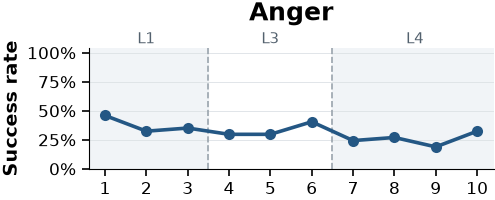

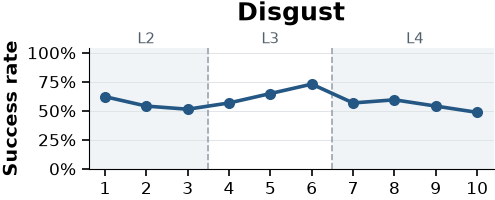

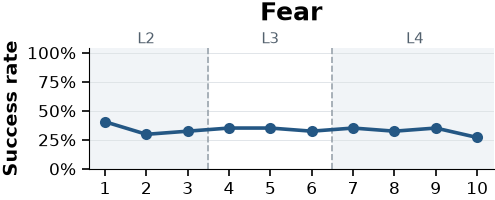

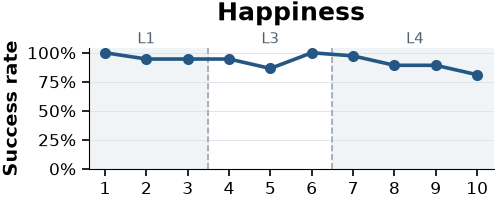

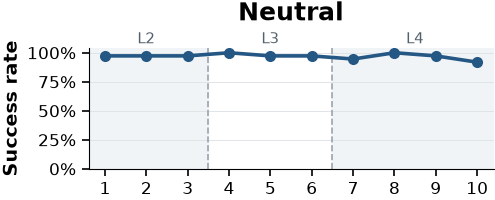

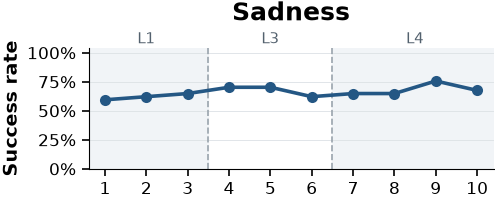

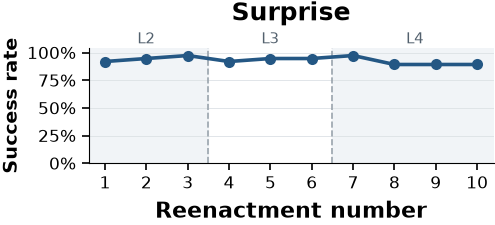

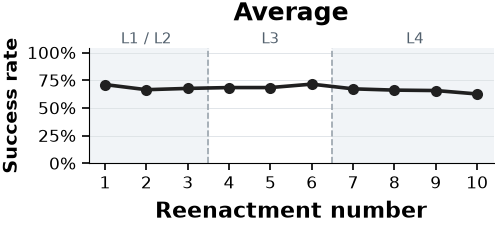

In [9]:
with plt.rc_context(PLOT_STYLE):
    for expression in PANEL_ORDER:
        figure = plot_category_chart(expression)
        try:
            export_figure(
                figure,
                f'gameplay_success_{expression.lower()}',
                title=f'EmojiHeroVR recognition success: {expression}',
                bbox_inches='tight',
                pad_inches=EXPORT_PADDING,
            )
            with BytesIO() as preview:
                figure.savefig(
                    preview,
                    format='png',
                    dpi=PREVIEW_DPI,
                    bbox_inches='tight',
                    pad_inches=EXPORT_PADDING,
                )
                display(Image(data=preview.getvalue(), format='png'))
        finally:
            plt.close(figure)

## 5. Early–late comparisons

Compare reenactments **1–3 versus 8–10** and **1–5 versus 6–10**.
Changes are late minus early rates, in percentage points. The overlapping
comparisons are descriptive, not independent evidence. The overall row pools
all categories and reports total counts.


In [10]:
# Overall recognition success within each expression category.
by_expression = (
    emojis.groupby('target_expression')
    .agg(
        n_emojis=('success', 'size'),
        n_successful=('success', 'sum'),
    )
    .reindex(CLASS_NAMES)
)

by_expression['success_rate_pct'] = 100 * by_expression['n_successful'] / by_expression['n_emojis']

# Compare reenactments 1–3 with 8–10, and 1–5 with 6–10.
comparisons = [
    (3, 'three', 'change_pp'),
    (5, 'five', 'change_five_pp'),
]

for window_size, window_name, change_column in comparisons:
    early = (
        emojis.loc[emojis['reenactment_number'].le(window_size)]
        .groupby('target_expression')['success']
        .mean()
        .reindex(CLASS_NAMES)
    )

    late = (
        emojis.loc[emojis['reenactment_number'].ge(11 - window_size)]
        .groupby('target_expression')['success']
        .mean()
        .reindex(CLASS_NAMES)
    )

    by_expression[f'first_{window_name}_success_pct'] = 100 * early
    by_expression[f'last_{window_name}_success_pct'] = 100 * late
    by_expression[change_column] = 100 * (late - early)

# Calculate an overall row directly from all reenactments.
overall_row = {
    'n_emojis': len(emojis),
    'n_successful': int(emojis['success'].sum()),
    'success_rate_pct': 100 * emojis['success'].mean(),
}

for window_size, window_name, change_column in comparisons:
    early_rate = emojis.loc[emojis['reenactment_number'].le(window_size), 'success'].mean()

    late_rate = emojis.loc[emojis['reenactment_number'].ge(11 - window_size), 'success'].mean()

    overall_row[f'first_{window_name}_success_pct'] = 100 * early_rate
    overall_row[f'last_{window_name}_success_pct'] = 100 * late_rate
    overall_row[change_column] = 100 * (late_rate - early_rate)

# Keep by_expression category-only for subsequent analyses.
by_expression_display = by_expression.copy()
by_expression_display.loc['Overall'] = overall_row

display(
    by_expression_display.style.format(
        {
            'n_emojis': '{:,.0f}',
            'n_successful': '{:,.0f}',
            'success_rate_pct': '{:.2f}',
            'first_three_success_pct': '{:.2f}',
            'last_three_success_pct': '{:.2f}',
            'change_pp': '{:+.2f}',
            'first_five_success_pct': '{:.2f}',
            'last_five_success_pct': '{:.2f}',
            'change_five_pp': '{:+.2f}',
        }
    )
    .apply(
        lambda row: ['font-weight: bold' if row.name == 'Overall' else ''] * len(row),
        axis=1,
    )
    .set_caption(
        'Recognition success (%); late minus early differences '
        'in percentage points. Overall counts are totals.'
    )
)

# Describe changes among the seven categories, excluding the overall row.
for _, window_name, change_column in comparisons:
    changes = by_expression[change_column]

    increased = changes.index[changes.gt(0)].tolist()
    decreased = changes.index[changes.lt(0)].tolist()
    unchanged = changes.index[changes.eq(0)].tolist()

    increased_names = f' ({", ".join(increased).lower()})' if increased else ''

    description = (
        f'**First {window_name} versus last {window_name}:** '
        f'success is higher for **{len(increased)} of '
        f'{len(CLASS_NAMES)} categories**{increased_names}, '
        f'lower for **{len(decreased)}**, and unchanged for '
        f'**{len(unchanged)}**. '
        f'The overall change is '
        f'**{overall_row[change_column]:+.2f} percentage points**.'
    )

    display(Markdown(description))

,n_emojis,n_successful,success_rate_pct,first_three_success_pct,last_three_success_pct,change_pp,first_five_success_pct,last_five_success_pct,change_five_pp
target_expression,,,,,,,,,
Anger,370,117,31.62,37.84,26.13,-11.71,34.59,28.65,-5.95
Disgust,370,215,58.11,55.86,54.05,-1.80,57.84,58.38,+0.54
Fear,370,124,33.51,34.23,31.53,-2.70,34.59,32.43,-2.16
Happiness,370,343,92.70,96.40,86.49,-9.91,94.05,91.35,-2.70
Neutral,370,359,97.03,97.30,96.40,-0.90,97.84,96.22,-1.62
Sadness,370,245,66.22,62.16,69.37,+7.21,65.41,67.03,+1.62
Surprise,370,344,92.97,94.59,89.19,-5.41,94.05,91.89,-2.16
Overall,"2,590","1,747",67.45,68.34,64.74,-3.60,68.34,66.56,-1.78


**First three versus last three:** success is higher for **1 of 7 categories** (sadness), lower for **6**, and unchanged for **0**. The overall change is **-3.60 percentage points**.

**First five versus last five:** success is higher for **2 of 7 categories** (disgust, sadness), lower for **5**, and unchanged for **0**. The overall change is **-1.78 percentage points**.

## 6. Participant-level comparisons

Repeat both comparisons for each participant across all seven categories:
21 outcomes per block for three-versus-three, and 35 for five-versus-five.
Order participants by their five-versus-five change and inspect category results
for everyone tied for the largest increase. Selecting the largest observed
change also selects for random variation; it does not establish adaptation.


In [11]:
# reenactment_number runs from 1 to 10 within participant and category.
CATEGORY_KEYS = ['participant_id', 'target_expression']

participant_summary = emojis.groupby('participant_id').agg(
    n_emojis=('success', 'size'),
    n_successful=('success', 'sum'),
)

participant_summary['overall_success_pct'] = (
    100 * participant_summary['n_successful'] / participant_summary['n_emojis']
)

participant_category_comparison = pd.DataFrame()
participant_change_rows = []

for window_size, window_name in [(3, 'three'), (5, 'five')]:
    # Count successes and outcomes separately for each participant/category.
    early = (
        emojis.loc[emojis['reenactment_number'].le(window_size)]
        .groupby(CATEGORY_KEYS)
        .agg(
            n_successful=('success', 'sum'),
            n_emojis=('success', 'size'),
        )
    )

    late = (
        emojis.loc[emojis['reenactment_number'].ge(11 - window_size)]
        .groupby(CATEGORY_KEYS)
        .agg(
            n_successful=('success', 'sum'),
            n_emojis=('success', 'size'),
        )
    )

    # Ensure every participant/category contributes equally to both blocks.
    expected_groups = len(participant_summary) * len(CLASS_NAMES)

    if (
        len(early) != expected_groups
        or not early.index.equals(late.index)
        or not early['n_emojis'].eq(window_size).all()
        or not late['n_emojis'].eq(window_size).all()
    ):
        raise ValueError(f'Incomplete participant/category data for window {window_size}.')

    first_column = f'first_{window_name}_success_pct'
    last_column = f'last_{window_name}_success_pct'
    change_column = f'change_{window_name}_pp'

    # Retain category-specific changes for inspecting individual participants.
    category_comparison = pd.DataFrame(
        {
            first_column: 100 * early['n_successful'] / window_size,
            last_column: 100 * late['n_successful'] / window_size,
            change_column: (100 * (late['n_successful'] - early['n_successful']) / window_size),
        }
    )

    participant_category_comparison = pd.concat(
        [participant_category_comparison, category_comparison],
        axis=1,
    )

    # Aggregate the seven equally represented categories per participant.
    early_successes = early['n_successful'].groupby('participant_id').sum()
    late_successes = late['n_successful'].groupby('participant_id').sum()
    outcomes_per_block = window_size * len(CLASS_NAMES)

    participant_summary[first_column] = 100 * early_successes / outcomes_per_block
    participant_summary[last_column] = 100 * late_successes / outcomes_per_block
    participant_summary[change_column] = (
        100 * (late_successes - early_successes) / outcomes_per_block
    )

    changes = participant_summary[change_column]

    participant_change_rows.append(
        {
            'comparison': f'First {window_size} vs last {window_size}',
            'outcomes_per_participant_per_block': outcomes_per_block,
            'n_increased': int(changes.gt(0).sum()),
            'n_unchanged': int(changes.eq(0).sum()),
            'n_decreased': int(changes.lt(0).sum()),
            'mean_change_pp': changes.mean(),
            'median_change_pp': changes.median(),
            'minimum_change_pp': changes.min(),
            'maximum_change_pp': changes.max(),
        }
    )

# Count the direction of category-specific changes for each participant.
category_changes = participant_category_comparison['change_five_pp']

for label, mask in [
    ('increased', category_changes.gt(0)),
    ('unchanged', category_changes.eq(0)),
    ('decreased', category_changes.lt(0)),
]:
    participant_summary[f'n_categories_{label}_five'] = (
        mask.groupby('participant_id').sum().astype(int)
    )

# Rank by the five-versus-five change; participant ID breaks ties.
participant_summary = participant_summary.sort_index().sort_values(
    'change_five_pp', ascending=False, kind='stable'
)

participant_change_summary = pd.DataFrame(participant_change_rows).set_index('comparison')

display(Markdown('### 6.1 Participant summary'))

participant_formats = {
    column: (
        '{:+.2f}' if column.endswith('_pp') else '{:.2f}' if column.endswith('_pct') else '{:,.0f}'
    )
    for column in participant_summary.columns
}

display(
    participant_summary.style.format(participant_formats).set_caption(
        'Participant-level success (%); changes in percentage points'
    )
)

display(Markdown('### 6.2 Distribution of changes'))

display(
    participant_change_summary.style.format(
        {
            'outcomes_per_participant_per_block': '{:.0f}',
            'n_increased': '{:.0f}',
            'n_unchanged': '{:.0f}',
            'n_decreased': '{:.0f}',
            'mean_change_pp': '{:+.2f}',
            'median_change_pp': '{:+.2f}',
            'minimum_change_pp': '{:+.2f}',
            'maximum_change_pp': '{:+.2f}',
        }
    )
)

# Include every participant tied for the largest five-versus-five change.
largest_change = participant_summary['change_five_pp'].max()
largest_change_ids = participant_summary.index[
    participant_summary['change_five_pp'].eq(largest_change)
]

display(
    Markdown(
        f'### 6.3 Largest observed change\n\n'
        f'**{largest_change:+.2f} percentage points**, observed for '
        f'participant(s) **{", ".join(map(str, largest_change_ids))}**. '
        'The category-specific results below show whether this change '
        'is distributed across categories.'
    )
)

largest_change_details = participant_category_comparison.loc[
    participant_category_comparison.index.get_level_values('participant_id').isin(
        largest_change_ids
    ),
    [
        'first_five_success_pct',
        'last_five_success_pct',
        'change_five_pp',
    ],
]

display(
    largest_change_details.style.format(
        {
            'first_five_success_pct': '{:.2f}',
            'last_five_success_pct': '{:.2f}',
            'change_five_pp': '{:+.2f}',
        }
    )
)

### 6.1 Participant summary

,n_emojis,n_successful,overall_success_pct,first_three_success_pct,last_three_success_pct,change_three_pp,first_five_success_pct,last_five_success_pct,change_five_pp,n_categories_increased_five,n_categories_unchanged_five,n_categories_decreased_five
participant_id,,,,,,,,,,,,
24,70,53,75.71,66.67,85.71,+19.05,65.71,85.71,+20.00,4,3,0
9,70,52,74.29,66.67,80.95,+14.29,65.71,82.86,+17.14,4,3,0
21,70,30,42.86,33.33,52.38,+19.05,34.29,51.43,+17.14,3,4,0
10,70,41,58.57,52.38,76.19,+23.81,51.43,65.71,+14.29,4,2,1
37,70,46,65.71,52.38,71.43,+19.05,60.00,71.43,+11.43,3,3,1
6,70,56,80.00,85.71,80.95,-4.76,77.14,82.86,+5.71,2,5,0
17,70,52,74.29,66.67,71.43,+4.76,71.43,77.14,+5.71,3,3,1
18,70,46,65.71,66.67,61.90,-4.76,62.86,68.57,+5.71,2,4,1
7,70,31,44.29,42.86,42.86,+0.00,42.86,45.71,+2.86,2,4,1


### 6.2 Distribution of changes

,outcomes_per_participant_per_block,n_increased,n_unchanged,n_decreased,mean_change_pp,median_change_pp,minimum_change_pp,maximum_change_pp
comparison,,,,,,,,
First 3 vs last 3,21,11,3,23,-3.60,-4.76,-42.86,+23.81
First 5 vs last 5,35,9,6,22,-1.78,-2.86,-31.43,+20.00


### 6.3 Largest observed change

**+20.00 percentage points**, observed for participant(s) **24**. The category-specific results below show whether this change is distributed across categories.

## 7. Level context

Prediction counts and recording-window durations provide context for changing
recognition opportunities. Durations come from the collected-data table in
thesis Section 5.7, not from this log. Recording windows include a preceding
buffer and differ from the gameplay recognition interval.


In [12]:
by_level = emojis.groupby('level_id').agg(
    n_emojis=('success', 'size'),
    n_successful=('success', 'sum'),
    mean_valid_predictions=('n_valid_predictions', 'mean'),
)
by_level['success_rate_pct'] = 100 * by_level['n_successful'] / by_level['n_emojis']
# Contextual values from the thesis; not an estimate from timestamps in this file.
by_level['mean_recording_window_s_thesis'] = pd.Series({1: 2.14, 2: 2.14, 3: 2.00, 4: 1.61})
display(
    by_level.style.format(
        {
            'n_emojis': '{:,.0f}',
            'n_successful': '{:,.0f}',
            'mean_valid_predictions': '{:.2f}',
            'success_rate_pct': '{:.2f}',
            'mean_recording_window_s_thesis': '{:.2f}',
        }
    )
)

,n_emojis,n_successful,mean_valid_predictions,success_rate_pct,mean_recording_window_s_thesis
level_id,,,,,
1,333,218,8.71,65.47,2.14
2,444,313,8.70,70.50,2.14
3,777,539,8.72,69.37,2.00
4,"1,036",677,6.63,65.35,1.61


## 8. Optional exports

Write enabled CSV tables and JSON provenance to `results/`. Category-only and
pooled expression summaries are exported separately. With all export flags
disabled, no external result files or output directories are created.


In [13]:
if EXPORT_CSV:
    RESULT_DIR.mkdir(parents=True, exist_ok=True)
    tables = {
        'analysis_environment': (pd.Series(versions, name='Version').to_frame(), True),
        'data_quality_counts': (pd.Series(quality_counts, name='Count').to_frame(), True),
        'success_by_presentation': (by_presentation, False),
        'success_rates_by_reenactment': (presentation_rates, True),
        'success_by_expression': (by_expression, True),
        'success_by_expression_with_overall': (by_expression_display, True),
        'success_by_participant': (participant_summary, True),
        'success_by_participant_and_expression': (participant_category_comparison, True),
        'participant_change_summary': (participant_change_summary, True),
        'largest_participant_changes': (largest_change_details, True),
        'success_by_level': (by_level, True),
    }
    for filename, (table, include_index) in tables.items():
        table.to_csv(RESULT_DIR / f'{filename}.csv', index=include_index, float_format='%.8f')
    print(f'Exported {len(tables)} CSV tables to {RESULT_DIR}/.')

if EXPORT_METADATA:
    RESULT_DIR.mkdir(parents=True, exist_ok=True)
    requirements_path = Path('requirements.txt')
    metadata = {
        'input_file': INPUT_PATH.as_posix(),
        'input_sha256': hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest(),
        'requirements_sha256': (
            hashlib.sha256(requirements_path.read_bytes()).hexdigest()
            if requirements_path.is_file()
            else None
        ),
        'outcome': 'At least one logged prediction matches the prompted expression per participant-level-emoji.',
        'ordering': 'level_id, then emoji_id; reenactment numbers continue across levels within each category.',
        'versions': versions,
        'quality_counts': {name: int(value) for name, value in quality_counts.items()},
        'successful_emojis': total_success,
        'total_emojis': len(emojis),
        'overall_success_pct': float(100 * emojis['success'].mean()),
        'recording_window_duration_source': 'Thesis Section 5.7, collected-data overview table.',
        'formal_statistical_tests': False,
    }
    (RESULT_DIR / 'analysis_metadata.json').write_text(
        json.dumps(metadata, indent=2) + '\n', encoding='utf-8'
    )
    print(f'Exported analysis metadata to {RESULT_DIR}/analysis_metadata.json.')

## 9. Interpretation

Recognition success does not increase consistently across categories.
Individual increases and decreases remain descriptive: changing difficulty,
shorter recording windows, fixed ordering, prior expression training and game
familiarisation limit inferences about learning. No significance tests are performed.

Recognition rates do not measure facial-movement diversity. Recognition-based
rewards may still discourage expression variants that the model finds difficult,
including before the recorded session. Manual annotation can assess recorded
expressions but cannot recover variants that participants never produced.
